**Statistics, Data Visualization & Exploratory Data Analysis**

Healthcare – Diabetes Dataset

Tools Used: Python, Pandas, NumPy, Matplotlib, Seaborn

Objective: To perform statistical analysis, data visualization, data cleaning, correlation analysis, outlier detection, and exploratory data analysis on a healthcare dataset.


In [2]:
%pip install seaborn

Note: you may need to restart the kernel to use updated packages.



[notice] A new release of pip is available: 26.1.2 -> 26.2.1
[notice] To update, run: python.exe -m pip install --upgrade pip


In [3]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

In [42]:
import os

os.makedirs("visualizations", exist_ok=True)

In [4]:
df = pd.read_csv("diabetes.csv")
df.head()

,Pregnancies,Glucose,BloodPressure,SkinThickness,Insulin,BMI,DiabetesPedigreeFunction,Age,Outcome
0,6,148,72,35,0,33.6,0.627,50,1
1,1,85,66,29,0,26.6,0.351,31,0
2,8,183,64,0,0,23.3,0.672,32,1
3,1,89,66,23,94,28.1,0.167,21,0
4,0,137,40,35,168,43.1,2.288,33,1


In [5]:
df.shape

(768, 9)

In [6]:
df.columns.tolist()

['Pregnancies',
 'Glucose',
 'BloodPressure',
 'SkinThickness',
 'Insulin',
 'BMI',
 'DiabetesPedigreeFunction',
 'Age',
 'Outcome']

In [7]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 768 entries, 0 to 767
Data columns (total 9 columns):
 #   Column                    Non-Null Count  Dtype  
---  ------                    --------------  -----  
 0   Pregnancies               768 non-null    int64  
 1   Glucose                   768 non-null    int64  
 2   BloodPressure             768 non-null    int64  
 3   SkinThickness             768 non-null    int64  
 4   Insulin                   768 non-null    int64  
 5   BMI                       768 non-null    float64
 6   DiabetesPedigreeFunction  768 non-null    float64
 7   Age                       768 non-null    int64  
 8   Outcome                   768 non-null    int64  
dtypes: float64(2), int64(7)
memory usage: 54.1 KB


In [8]:
df.describe()

,Pregnancies,Glucose,BloodPressure,SkinThickness,Insulin,BMI,DiabetesPedigreeFunction,Age,Outcome
count,768.000000,768.000000,768.000000,768.000000,768.000000,768.000000,768.000000,768.000000,768.000000
mean,3.845052,120.894531,69.105469,20.536458,79.799479,31.992578,0.471876,33.240885,0.348958
std,3.369578,31.972618,19.355807,15.952218,115.244002,7.884160,0.331329,11.760232,0.476951
min,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.078000,21.000000,0.000000
25%,1.000000,99.000000,62.000000,0.000000,0.000000,27.300000,0.243750,24.000000,0.000000
50%,3.000000,117.000000,72.000000,23.000000,30.500000,32.000000,0.372500,29.000000,0.000000
75%,6.000000,140.250000,80.000000,32.000000,127.250000,36.600000,0.626250,41.000000,1.000000
max,17.000000,199.000000,122.000000,99.000000,846.000000,67.100000,2.420000,81.000000,1.000000


**Task 1: Statistical Analysis – Mean, Median & Mode**

Calculated the mean, median, and mode of the Glucose variable.
These measures help understand the central tendency of glucose measurements
in the dataset.

In [9]:
mean_glucose = df["Glucose"].mean()
median_glucose = df["Glucose"].median()
mode_glucose = df["Glucose"].mode()[0]

print("Mean Glucose:", mean_glucose)
print("Median Glucose:", median_glucose)
print("Mode Glucose:", mode_glucose)

Mean Glucose: 120.89453125
Median Glucose: 117.0
Mode Glucose: 99



**Mean:** Represents the average glucose level in the dataset.
**Median:** Represents the middle glucose value when all observations are ordered.
**Mode:** Represents the most frequently occurring glucose value.
These three measures provide different views of the central tendency of the
Glucose variable.
    


**Task 2: Variance & Standard Deviation**

Calculated the variance and standard deviation of the Glucose variable.
These measures help understand how widely glucose measurements are spread
around the mean.
    

In [10]:
variance_glucose = df["Glucose"].var()
std_glucose = df["Glucose"].std()

print("Variance of Glucose:", variance_glucose)
print("Standard Deviation of Glucose:", std_glucose)

Variance of Glucose: 1022.2483142519557
Standard Deviation of Glucose: 31.97261819513622



Variance measures the overall spread of glucose values from the mean.
Standard deviation represents the typical amount of variation in the
glucose measurements.
A larger standard deviation indicates greater variation in the observations



**Task 3: Correlation & Probability Basics**

Calculated the correlation between BMI and Glucose.
Both variables are numerical, so correlation can be used to examine whether
they have a linear relationship.
    

In [11]:
correlation = df["BMI"].corr(df["Glucose"])

print("Correlation between BMI and Glucose:", correlation)

Correlation between BMI and Glucose: 0.22107106945898297



Interpretation

The correlation coefficient ranges from -1 to +1.

- A positive value indicates a positive relationship.
- A negative value indicates a negative relationship.
- A value close to zero indicates a weak linear relationship.

The actual result obtained above is used to describe the relationship in
this dataset.
    


3.2 Probability

We calculate the probability that a randomly selected patient has a recorded
diabetes outcome of 1.
    

In [12]:
diabetic_patients = (df["Outcome"] == 1).sum()
total_patients = len(df)

probability = diabetic_patients / total_patients

print("Patients with Outcome = 1:", diabetic_patients)
print("Total Patients:", total_patients)
print("Probability:", probability)

Patients with Outcome = 1: 268
Total Patients: 768
Probability: 0.3489583333333333



Probability is calculated using:
**Probability = Favorable Outcomes / Total Outcomes**
The result represents the proportion of patients in this dataset with a
recorded Outcome value of 1.
    


**Task 4: Outlier Detection**

Used the Interquartile Range (IQR) method to identify potential outliers
in the BMI variable.
Outlier detection helps identify unusually high or low observations that
may influence statistical analysis.
    

In [13]:
Q1 = df["BMI"].quantile(0.25)
Q3 = df["BMI"].quantile(0.75)

IQR = Q3 - Q1

lower_bound = Q1 - 1.5 * IQR
upper_bound = Q3 + 1.5 * IQR

print("Q1:", Q1)
print("Q3:", Q3)
print("IQR:", IQR)
print("Lower Bound:", lower_bound)
print("Upper Bound:", upper_bound)

Q1: 27.3
Q3: 36.6
IQR: 9.3
Lower Bound: 13.35
Upper Bound: 50.550000000000004


In [14]:
outliers = df[
    (df["BMI"] < lower_bound) |
    (df["BMI"] > upper_bound)
]

print("Number of BMI Outliers:", len(outliers))

outliers[["BMI"]].head(20)

Number of BMI Outliers: 19


,BMI
9,0.0
49,0.0
60,0.0
81,0.0
120,53.2
125,55.0
145,0.0
177,67.1
193,52.3
247,52.3



The IQR method identifies observations below the lower bound or above the
upper bound as potential outliers.

Outliers can influence measures such as the mean and standard deviation and
can also affect visualizations and correlation analysis. 
    


**Task 5: Matplotlib Visualization**

Five visualizations are created using Matplotlib:


**1. Line Chart**

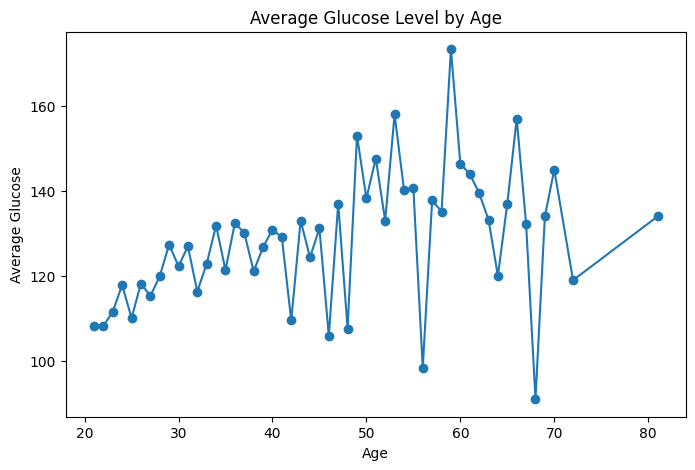

In [43]:
age_glucose = df.groupby("Age")["Glucose"].mean()

plt.figure(figsize=(8, 5))
plt.plot(age_glucose.index, age_glucose.values, marker="o")

plt.title("Average Glucose Level by Age")
plt.xlabel("Age")
plt.ylabel("Average Glucose")

plt.savefig(
    "visualizations/average_glucose_by_age.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()

The line chart shows how the average glucose measurement changes across
different age values.

**2. Bar Chart**

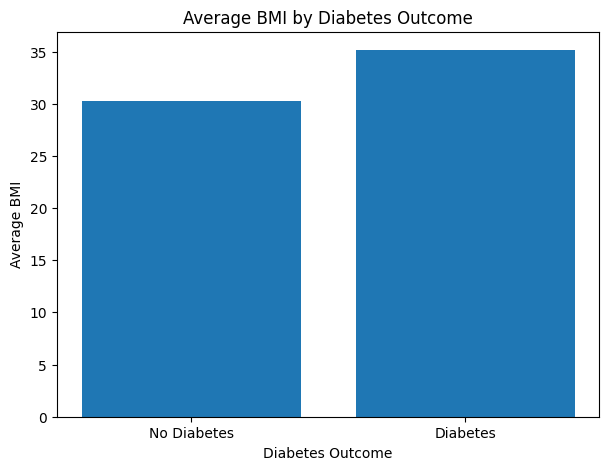

In [44]:
outcome_bmi = df.groupby("Outcome")["BMI"].mean()

plt.figure(figsize=(7, 5))

plt.bar(
    ["No Diabetes", "Diabetes"],
    outcome_bmi.values
)

plt.title("Average BMI by Diabetes Outcome")
plt.xlabel("Diabetes Outcome")
plt.ylabel("Average BMI")

plt.savefig(
    "visualizations/average_bmi_by_outcome.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()

The bar chart compares the average BMI between the two recorded diabetes
outcome groups.

**3. Pie Chart**

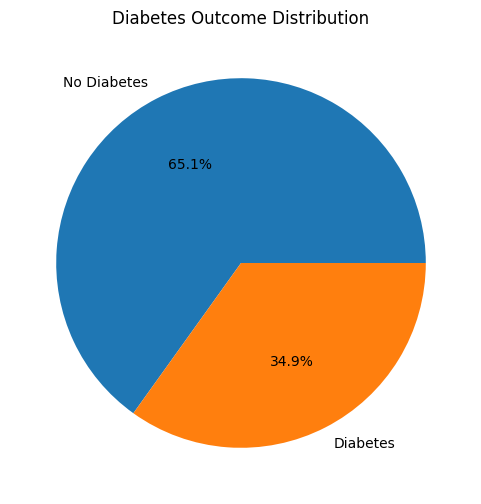

In [47]:
outcome_counts = df["Outcome"].value_counts().sort_index()

plt.figure(figsize=(6, 6))

plt.pie(
    outcome_counts,
    labels=["No Diabetes", "Diabetes"],
    autopct="%1.1f%%"
)

plt.title("Diabetes Outcome Distribution")

plt.savefig(
    "visualizations/diabetes_outcome_distribution.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()

The pie chart shows the proportion of records belonging to each recorded
diabetes outcome category.

**4. Histogram**

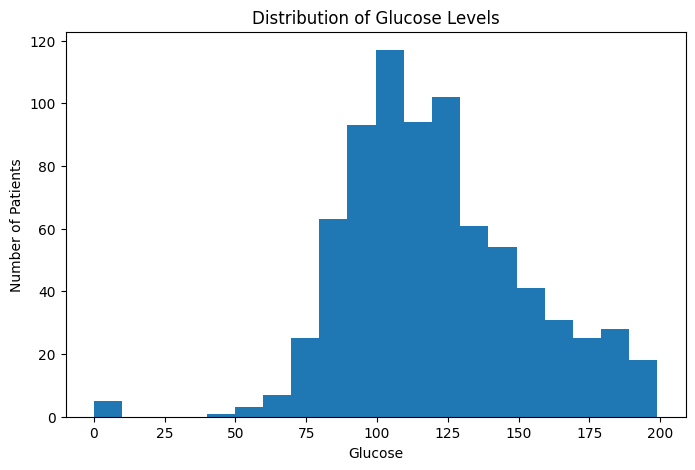

In [48]:
plt.figure(figsize=(8, 5))

plt.hist(df["Glucose"].dropna(), bins=20)

plt.title("Distribution of Glucose Levels")
plt.xlabel("Glucose")
plt.ylabel("Number of Patients")

plt.savefig(
    "visualizations/glucose_distribution.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()

The histogram shows the distribution of glucose measurements and helps
understand their spread and concentration.

**5. Scatter Plot**

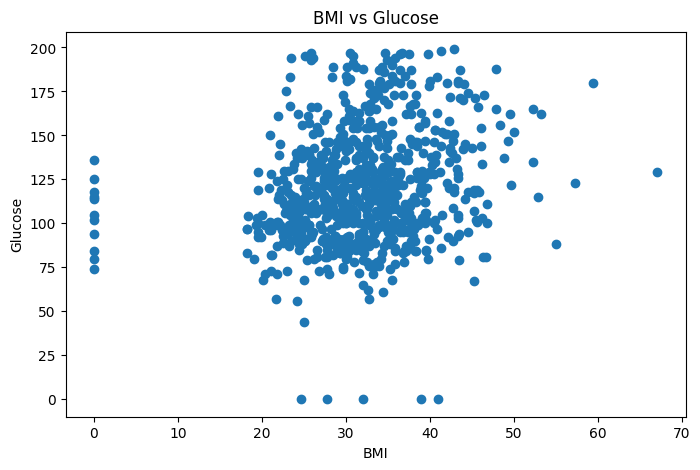

In [49]:
plt.figure(figsize=(8, 5))

plt.scatter(df["BMI"], df["Glucose"])

plt.title("BMI vs Glucose")
plt.xlabel("BMI")
plt.ylabel("Glucose")

plt.savefig(
    "visualizations/bmi_vs_glucose.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()


**Task 6: Seaborn Visualization**

The following visualizations are created using Seaborn:


**1. Count Plot**

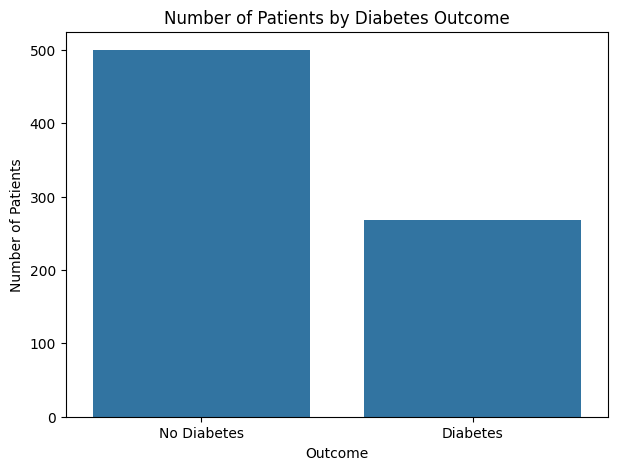

In [50]:
plt.figure(figsize=(7, 5))

sns.countplot(data=df, x="Outcome")

plt.title("Number of Patients by Diabetes Outcome")
plt.xlabel("Outcome")
plt.ylabel("Number of Patients")

plt.xticks([0, 1], ["No Diabetes", "Diabetes"])

plt.savefig(
    "visualizations/patient_count_by_outcome.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()

**2. Box Plot**

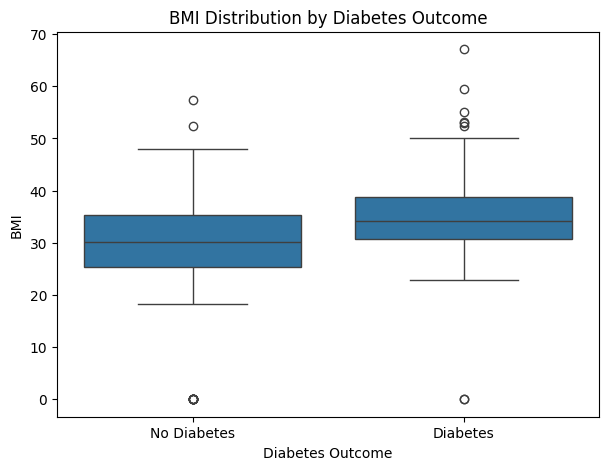

In [51]:
plt.figure(figsize=(7, 5))

sns.boxplot(data=df, x="Outcome", y="BMI")

plt.title("BMI Distribution by Diabetes Outcome")
plt.xlabel("Diabetes Outcome")
plt.ylabel("BMI")

plt.xticks([0, 1], ["No Diabetes", "Diabetes"])

plt.savefig(
    "visualizations/bmi_distribution_by_outcome.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()

**3. Heatmap**

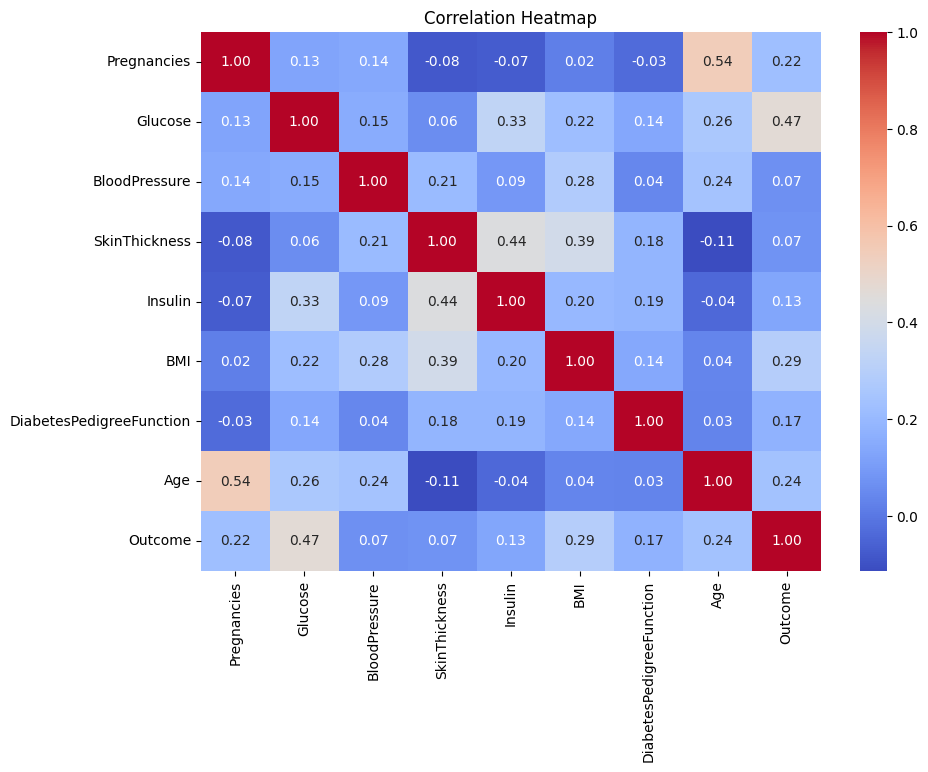

In [52]:
plt.figure(figsize=(10, 7))

correlation_matrix = df.corr(numeric_only=True)

sns.heatmap(
    correlation_matrix,
    annot=True,
    cmap="coolwarm",
    fmt=".2f"
)

plt.title("Correlation Heatmap")

plt.savefig(
    "visualizations/correlation_heatmap.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()

**4. Pair Plot**

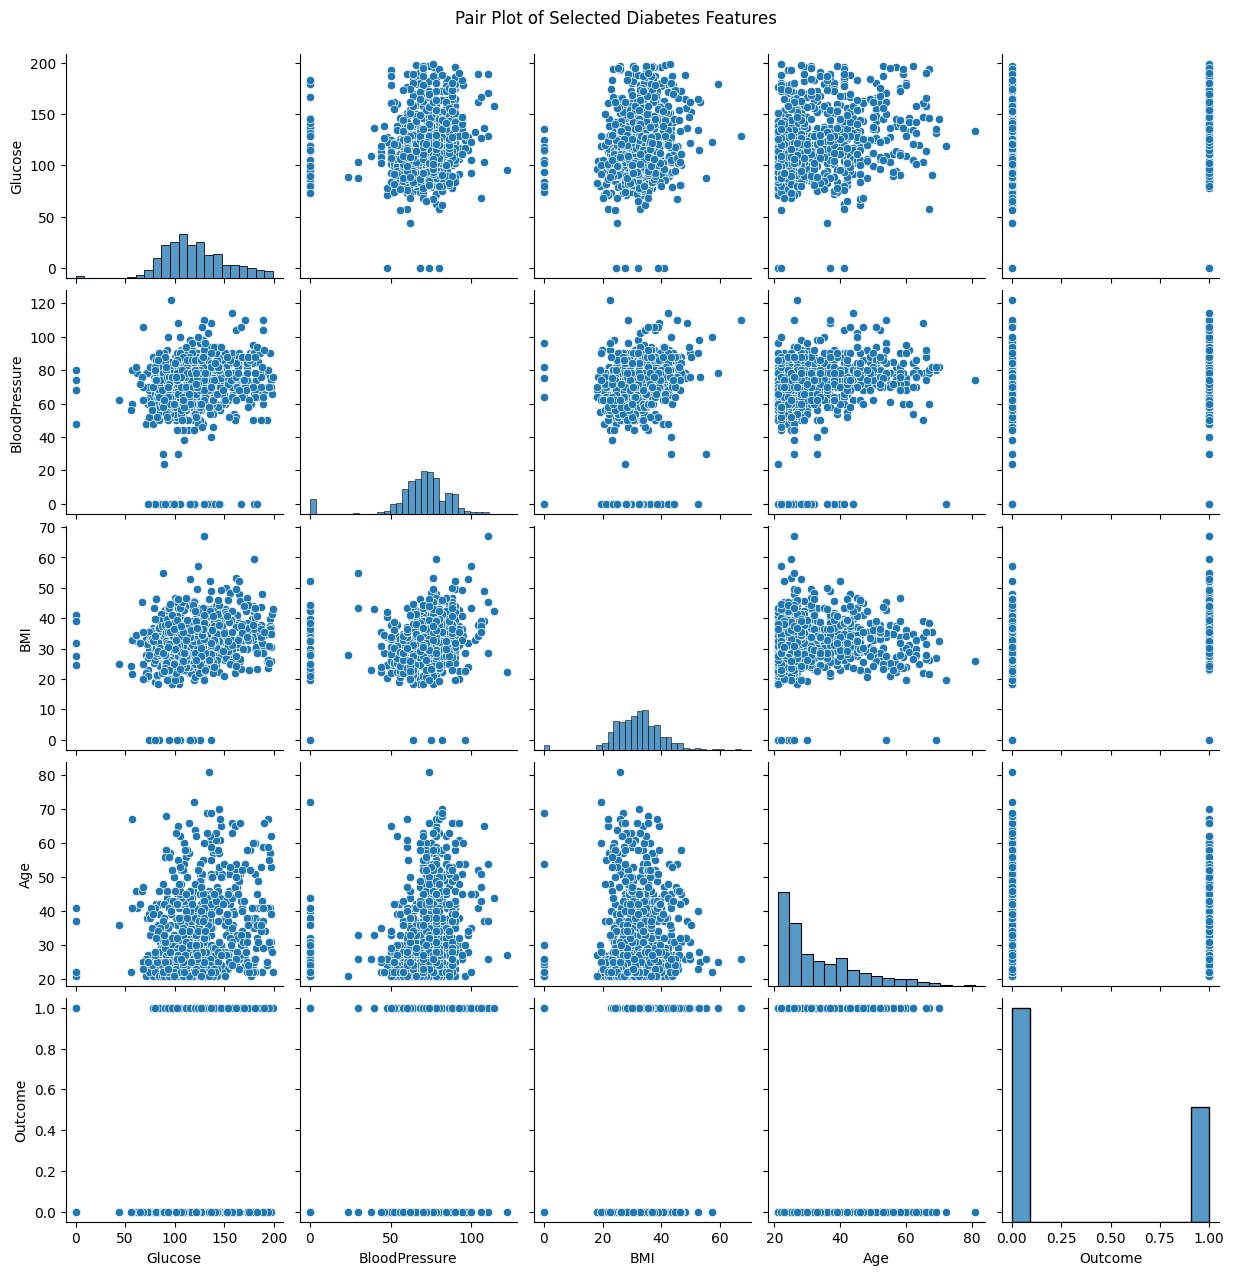

In [54]:
selected_columns = [
    "Glucose",
    "BloodPressure",
    "BMI",
    "Age",
    "Outcome"
]

pair_plot = sns.pairplot(df[selected_columns].dropna())

pair_plot.fig.suptitle(
    "Pair Plot of Selected Diabetes Features",
    y=1.02
)

pair_plot.savefig(
    "visualizations/pairplot_selected_features.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()

The visualization helps identify patterns, distributions, and relationships
between the selected healthcare variables.


**Task 7: Exploratory Data Analysis – Data Inspection & Cleaning**


In [24]:
print("Number of Rows and Columns:", df.shape)

Number of Rows and Columns: (768, 9)


In [25]:
print("Column Names:")
print(df.columns.tolist())

Column Names:
['Pregnancies', 'Glucose', 'BloodPressure', 'SkinThickness', 'Insulin', 'BMI', 'DiabetesPedigreeFunction', 'Age', 'Outcome']


In [26]:
print("Data Types:")
print(df.dtypes)

Data Types:
Pregnancies                   int64
Glucose                       int64
BloodPressure                 int64
SkinThickness                 int64
Insulin                       int64
BMI                         float64
DiabetesPedigreeFunction    float64
Age                           int64
Outcome                       int64
dtype: object


In [27]:
print("Statistical Summary:")
df.describe()

Statistical Summary:


,Pregnancies,Glucose,BloodPressure,SkinThickness,Insulin,BMI,DiabetesPedigreeFunction,Age,Outcome
count,768.000000,768.000000,768.000000,768.000000,768.000000,768.000000,768.000000,768.000000,768.000000
mean,3.845052,120.894531,69.105469,20.536458,79.799479,31.992578,0.471876,33.240885,0.348958
std,3.369578,31.972618,19.355807,15.952218,115.244002,7.884160,0.331329,11.760232,0.476951
min,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.078000,21.000000,0.000000
25%,1.000000,99.000000,62.000000,0.000000,0.000000,27.300000,0.243750,24.000000,0.000000
50%,3.000000,117.000000,72.000000,23.000000,30.500000,32.000000,0.372500,29.000000,0.000000
75%,6.000000,140.250000,80.000000,32.000000,127.250000,36.600000,0.626250,41.000000,1.000000
max,17.000000,199.000000,122.000000,99.000000,846.000000,67.100000,2.420000,81.000000,1.000000


In [28]:
print("Missing Values:")
print(df.isnull().sum())

Missing Values:
Pregnancies                 0
Glucose                     0
BloodPressure               0
SkinThickness               0
Insulin                     0
BMI                         0
DiabetesPedigreeFunction    0
Age                         0
Outcome                     0
dtype: int64


In [29]:
columns_with_zero_issue = [
    "Glucose",
    "BloodPressure",
    "SkinThickness",
    "Insulin",
    "BMI"
]

for column in columns_with_zero_issue:
    print(column, ":", (df[column] == 0).sum())

Glucose : 5
BloodPressure : 35
SkinThickness : 227
Insulin : 374
BMI : 11


In [30]:
df_clean = df.copy()

for column in columns_with_zero_issue:
    df_clean[column] = df_clean[column].replace(0, np.nan)

In [31]:
print(df_clean.isnull().sum())

Pregnancies                   0
Glucose                       5
BloodPressure                35
SkinThickness               227
Insulin                     374
BMI                          11
DiabetesPedigreeFunction      0
Age                           0
Outcome                       0
dtype: int64


**Before and After Data Cleaning**

The original dataset was inspected for missing values, invalid zero measurements, and duplicate rows. Invalid zero measurements in selected medical measurement columns were treated as missing values and filled using the median. The cleaned dataset was checked again to confirm the results.

In [32]:
for column in columns_with_zero_issue:
    df_clean[column] = df_clean[column].fillna(
        df_clean[column].median()
    )  

In [39]:
print("Before Cleaning:")
display(df.head())

print("\nMissing Values Before Cleaning:")
print(df.isnull().sum())

print("\nInvalid Zero Measurements:")
for column in columns_with_zero_issue:
    print(column, ":", (df[column] == 0).sum())

Before Cleaning:


,Pregnancies,Glucose,BloodPressure,SkinThickness,Insulin,BMI,DiabetesPedigreeFunction,Age,Outcome
0,6,148,72,35,0,33.6,0.627,50,1
1,1,85,66,29,0,26.6,0.351,31,0
2,8,183,64,0,0,23.3,0.672,32,1
3,1,89,66,23,94,28.1,0.167,21,0
4,0,137,40,35,168,43.1,2.288,33,1



Missing Values Before Cleaning:
Pregnancies                 0
Glucose                     0
BloodPressure               0
SkinThickness               0
Insulin                     0
BMI                         0
DiabetesPedigreeFunction    0
Age                         0
Outcome                     0
dtype: int64

Invalid Zero Measurements:
Glucose : 5
BloodPressure : 35
SkinThickness : 227
Insulin : 374
BMI : 11


In [41]:
print("After Cleaning:")
display(df_clean.head())

print("\nMissing Values After Cleaning:")
print(df_clean.isnull().sum())


After Cleaning:


,Pregnancies,Glucose,BloodPressure,SkinThickness,Insulin,BMI,DiabetesPedigreeFunction,Age,Outcome
0,6,148.0,72.0,35.0,125.0,33.6,0.627,50,1
1,1,85.0,66.0,29.0,125.0,26.6,0.351,31,0
2,8,183.0,64.0,29.0,125.0,23.3,0.672,32,1
3,1,89.0,66.0,23.0,94.0,28.1,0.167,21,0
4,0,137.0,40.0,35.0,168.0,43.1,2.288,33,1



Missing Values After Cleaning:
Pregnancies                 0
Glucose                     0
BloodPressure               0
SkinThickness               0
Insulin                     0
BMI                         0
DiabetesPedigreeFunction    0
Age                         0
Outcome                     0
dtype: int64


In [34]:
print("Duplicate rows:", df_clean.duplicated().sum())

Duplicate rows: 0


In [35]:
print("Outcome values:", df_clean["Outcome"].unique())

Outcome values: [1 0]



**Task 8: EDA – Correlation & Insights**

Analyzed relationships between the healthcare variables using correlation analysis and visualizations.
EDA helps identify patterns, relationships, and trends in the dataset. It also helps us understand which variables are associated with the recorded diabetes outcome.


In [36]:
correlation = df_clean.corr(numeric_only=True)
correlation

,Pregnancies,Glucose,BloodPressure,SkinThickness,Insulin,BMI,DiabetesPedigreeFunction,Age,Outcome
Pregnancies,1.000000,0.128213,0.208615,0.081770,0.025047,0.021559,-0.033523,0.544341,0.221898
Glucose,0.128213,1.000000,0.218937,0.192615,0.419451,0.231049,0.137327,0.266909,0.492782
BloodPressure,0.208615,0.218937,1.000000,0.191892,0.045363,0.281257,-0.002378,0.324915,0.165723
SkinThickness,0.081770,0.192615,0.191892,1.000000,0.155610,0.543205,0.102188,0.126107,0.214873
Insulin,0.025047,0.419451,0.045363,0.155610,1.000000,0.180241,0.126503,0.097101,0.203790
BMI,0.021559,0.231049,0.281257,0.543205,0.180241,1.000000,0.153438,0.025597,0.312038
DiabetesPedigreeFunction,-0.033523,0.137327,-0.002378,0.102188,0.126503,0.153438,1.000000,0.033561,0.173844
Age,0.544341,0.266909,0.324915,0.126107,0.097101,0.025597,0.033561,1.000000,0.238356
Outcome,0.221898,0.492782,0.165723,0.214873,0.203790,0.312038,0.173844,0.238356,1.000000


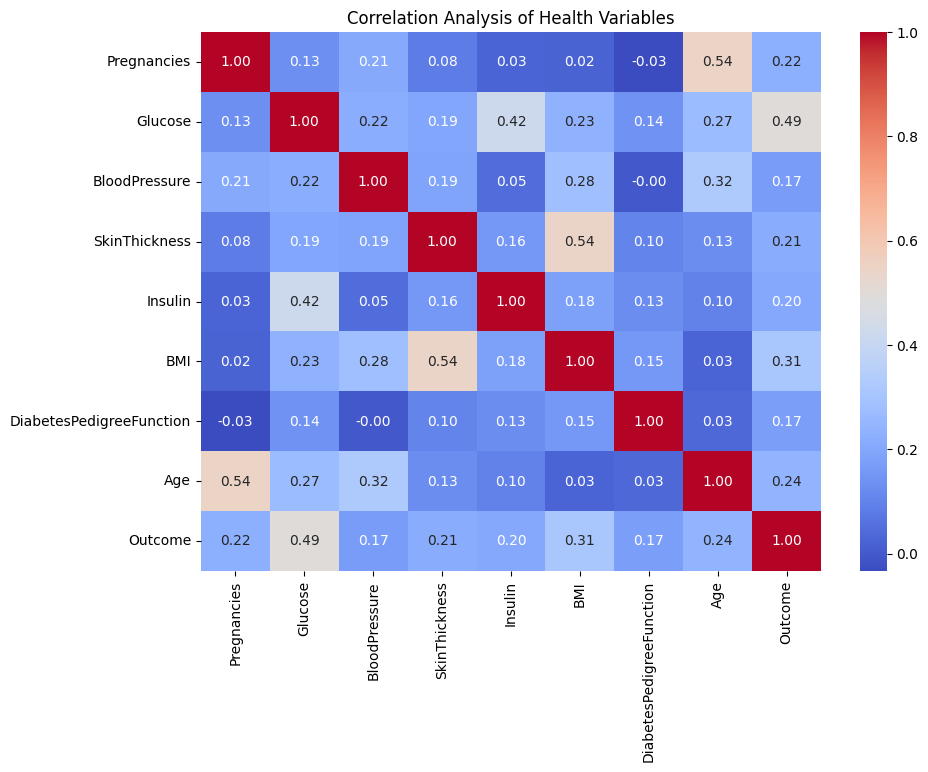

In [55]:
plt.figure(figsize=(10, 7))

sns.heatmap(
    correlation,
    annot=True,
    cmap="coolwarm",
    fmt=".2f"
)

plt.title("Correlation Analysis of Health Variables")

plt.savefig(
    "visualizations/health_variables_correlation.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()

In [38]:
outcome_corr = correlation["Outcome"].drop("Outcome")

outcome_corr = outcome_corr.sort_values(
    key=abs, ascending=False
)

print(outcome_corr)

Glucose                     0.492782
BMI                         0.312038
Age                         0.238356
Pregnancies                 0.221898
SkinThickness               0.214873
Insulin                     0.203790
DiabetesPedigreeFunction    0.173844
BloodPressure               0.165723
Name: Outcome, dtype: float64


**Key Insights**

**1. Glucose and Diabetes Outcome:** Glucose has the strongest positive correlation 
   with Outcome, with a value of 0.493. This indicates a moderate positive 
   relationship, meaning higher glucose measurements tend to be associated with 
   Outcome = 1 in this dataset.

**2. BMI and Diabetes Outcome:** BMI has a positive correlation of 0.312 with Outcome.
   This indicates a moderate positive relationship, although it is weaker than the 
   relationship between Glucose and Outcome.

**3. Age and Diabetes Outcome:** Age has a positive correlation of 0.238 with Outcome. 
   This indicates a weak positive relationship between age and the recorded diabetes
   outcome.

**Task 9: Data-Driven Business Recommendations**

**Recommendations**

**1. Prioritize screening and follow-up:** Since Glucose has the strongest            correlation with the recorded diabetes outcome (0.493), healthcare organizations    can conside glucose measurements when prioritizing screening and follow-up          assessments, alongside clinical guidelines and professional judgment.

**2. Consider multiple patient measurements:** BMI (0.312) and Age (0.238) also       show positive correlations with Outcome. Healthcare teams can consider these        variables together with other relevant clinical information when reviewing          patient records.